DATA_DIR: d:\SDT\Project Analitika Data\AgriDash-0.1\data\raw\biofarmaka
OUT_DIR : d:\SDT\Project Analitika Data\AgriDash-0.1\data\raw\biofarmaka\output

=== AUDIT luas_nasional | shape=(96, 3) | duplikat=0
Missing token per tahun:
 Tahun
2020    3
2021    3
2022    2
2023    3
2024    3
2025    5

=== AUDIT prod_nasional | shape=(96, 3) | duplikat=0
Missing token per tahun:
 Tahun
2020    0
2021    0
2022    0
2023    0
2024    0
2025    5

=== AUDIT luas_kec | shape=(162, 18) | duplikat=0
Missing token per tahun:
 Tahun
2020      0
2021      0
2022      0
2023     12
2024     74
2025    371

=== AUDIT prod_kec | shape=(162, 18) | duplikat=0
Missing token per tahun:
 Tahun
2020      0
2021      0
2022      1
2023     12
2024     68
2025    371

[kecamatan] rasio data terisi per tahun:
Tahun
2020    1.000
2021    1.000
2022    0.999
2023    0.972
2024    0.836
2025    0.141
-> tahun dibuang: [2025]

[nasional] rasio data terisi per tahun:
Tahun
2020    0.906
2021    0.906
2022    0.938

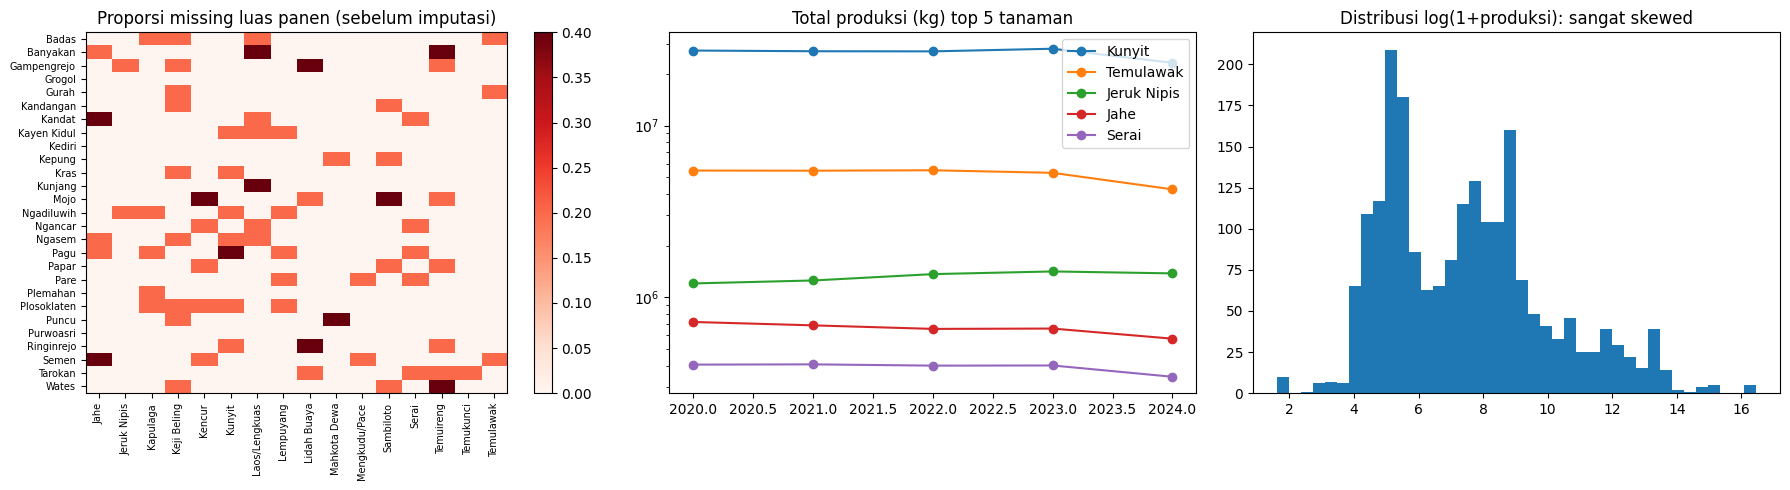


Selesai. kec: (2160, 11) | nas: (96, 8)
Output tersimpan di: d:\SDT\Project Analitika Data\AgriDash-0.1\data\raw\biofarmaka\output


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------------------- 0. KONFIGURASI PATH
FILES = {
    "luas_nasional": "Luas_Panen_Biofarmaka.csv",
    "prod_nasional": "Total_Produksi_Biofarmaka.csv",
    "luas_kec": "Luas_Panen_Biofarmaka_per_kecamatan.csv",
    "prod_kec": "Total_Produksi_Biofarmaka_per_kecamatan.csv",
}

try:
    BASE = Path(__file__).resolve().parent      # dijalankan sebagai file .py
except NameError:
    BASE = Path.cwd()                           # dijalankan di notebook/interactive

def find_data_dir():
    kandidat = [BASE, BASE / "data", Path.cwd(), Path.cwd() / "data"]
    for d in kandidat:
        if all((d / f).exists() for f in FILES.values()):
            return d
    print("File CSV tidak ditemukan. Lokasi yang dicari:")
    for d in kandidat:
        print("  -", d)
    print("Isi folder skrip:", [p.name for p in BASE.iterdir()])
    raise FileNotFoundError("Taruh keempat CSV di folder yang sama dengan skrip, atau di subfolder 'data'.")

DATA_DIR = find_data_dir()
OUT_DIR = DATA_DIR / "output"
OUT_DIR.mkdir(exist_ok=True)
print("DATA_DIR:", DATA_DIR)
print("OUT_DIR :", OUT_DIR)

MISSING_TOKENS = ["-", "", " ", "NA", "N/A", "na", "null", "..."]
YEAR_MIN_VALID_RATIO = 0.30     # tahun dibuang jika <30% selnya terisi (2025 hanya ~14%)

# ---------------------------------------------------------------- 1. LOAD
def load_raw(path):
    # utf-8-sig membuang BOM; dtype=str agar '-' tidak merusak tipe kolom
    return pd.read_csv(path, encoding="utf-8-sig", dtype=str, keep_default_na=False)

raw = {k: load_raw(DATA_DIR / v) for k, v in FILES.items()}

# ---------------------------------------------------------------- 2. AUDIT
def audit(df, name):
    m = df.isin(MISSING_TOKENS)
    print(f"\n=== AUDIT {name} | shape={df.shape} | duplikat={df.duplicated().sum()}")
    print("Missing token per tahun:\n", m.groupby(df["Tahun"]).sum().sum(axis=1).to_string())

for k, d in raw.items():
    audit(d, k)

# ---------------------------------------------------------------- 3. CLEAN HELPERS
def clean_text(s):
    return s.astype(str).str.strip().str.replace(r"\s+", " ", regex=True)

def to_numeric(df, cols):
    out = df.copy()
    for c in cols:
        s = clean_text(out[c]).replace(MISSING_TOKENS, np.nan)
        s = s.str.replace(r"[^\d,.\-]", "", regex=True)   # buang karakter non-angka
        out[c] = pd.to_numeric(s, errors="coerce")
    return out

def clean_national(df, value_col, value_name):
    d = df.copy()
    d["Tahun"] = pd.to_numeric(d["Tahun"], errors="coerce").astype("Int64")
    d["Jenis Tanaman"] = clean_text(d["Jenis Tanaman"])
    # pisahkan nama tanaman dan satuan: 'Jahe/Ginger(m2)' -> Jahe | m2
    d["Satuan"] = d["Jenis Tanaman"].str.extract(r"\(([^)]*)\)\s*$")[0]
    d["Tanaman"] = (d["Jenis Tanaman"].str.replace(r"\([^)]*\)\s*$", "", regex=True)
                    .str.split("/").str[0].str.strip())
    d = to_numeric(d, [value_col]).rename(columns={value_col: value_name})
    d = d.drop(columns="Jenis Tanaman").drop_duplicates(["Tahun", "Tanaman"])
    return d[["Tahun", "Tanaman", "Satuan", value_name]]

def clean_kecamatan(df, value_name):
    d = df.copy()
    d["Tahun"] = pd.to_numeric(d["Tahun"], errors="coerce").astype("Int64")
    d["Kecamatan"] = clean_text(d["Kecamatan"]).str.title()
    val_cols = [c for c in d.columns if c not in ("Tahun", "Kecamatan")]
    d = to_numeric(d, val_cols)
    # wide -> long; nama tanaman diambil dari 'Luas Panen Jahe (..) (M2)'
    long = d.melt(["Tahun", "Kecamatan"], var_name="kolom", value_name=value_name)
    long["Tanaman"] = (long["kolom"]
                       .str.replace(r"^(Luas Panen|Produksi)\s+", "", regex=True)
                       .str.replace(r"\s*\(.*$", "", regex=True).str.strip())
    long["Satuan"] = long["kolom"].str.extract(r"\(([^()]*)\)\s*$")[0]
    return (long.drop(columns="kolom").drop_duplicates(["Tahun", "Kecamatan", "Tanaman"])
            [["Tahun", "Kecamatan", "Tanaman", "Satuan", value_name]])

nas_luas = clean_national(raw["luas_nasional"], "Luas Panen Tanaman Biofarmaka", "luas_panen")
nas_prod = clean_national(raw["prod_nasional"], "Produksi Tanaman Biofarmaka", "produksi_kg")
kec_luas = clean_kecamatan(raw["luas_kec"], "luas_panen")
kec_prod = clean_kecamatan(raw["prod_kec"], "produksi_kg")

# ---------------------------------------------------------------- 4. MERGE
# Satuan luas dipertahankan: m2 (rimpang/herba) vs pohon
kec = (kec_luas.rename(columns={"Satuan": "satuan_luas"})
       .merge(kec_prod.drop(columns="Satuan"), on=["Tahun", "Kecamatan", "Tanaman"],
              how="outer", validate="1:1"))
nas = (nas_luas.rename(columns={"Satuan": "satuan_luas"})
       .merge(nas_prod.drop(columns="Satuan"), on=["Tahun", "Tanaman"],
              how="outer", validate="1:1"))

# ---------------------------------------------------------------- 5. TAHUN KOSONG
def drop_empty_years(df, cols, name):
    ratio = df.groupby("Tahun")[cols].apply(lambda x: x.notna().mean().mean())
    print(f"\n[{name}] rasio data terisi per tahun:\n{ratio.round(3).to_string()}")
    bad = ratio[ratio < YEAR_MIN_VALID_RATIO].index
    print(f"-> tahun dibuang: {[int(b) for b in bad]}")
    return df[~df["Tahun"].isin(bad)].copy()

kec = drop_empty_years(kec, ["luas_panen", "produksi_kg"], "kecamatan")
nas = drop_empty_years(nas, ["luas_panen", "produksi_kg"], "nasional")

# ---------------------------------------------------------------- 6. MISSING VALUE
# Indikator missing disimpan SEBELUM imputasi ('-' bisa berarti tidak ada tanaman / belum dilaporkan)
for c in ["luas_panen", "produksi_kg"]:
    kec[f"{c}_missing"] = kec[c].isna().astype(int)
    nas[f"{c}_missing"] = nas[c].isna().astype(int)

def impute_series(df, keys, cols, strategy="interpolate"):
    """'none'        -> biarkan NaN
       'zero'        -> isi 0 (asumsi '-' = tidak ada produksi)
       'interpolate' -> interpolasi linear HANYA di antara dua titik valid (tanpa ekstrapolasi)"""
    df = df.sort_values(keys + ["Tahun"]).copy()
    for c in cols:
        if strategy == "zero":
            df[c] = df[c].fillna(0)
        elif strategy == "interpolate":
            df[c] = (df.groupby(keys)[c]
                     .transform(lambda s: s.interpolate(method="linear", limit_area="inside")))
    return df

kec = impute_series(kec, ["Kecamatan", "Tanaman"], ["luas_panen", "produksi_kg"], "interpolate")
nas = impute_series(nas, ["Tanaman"], ["luas_panen", "produksi_kg"], "interpolate")
print("\nSisa NaN kecamatan setelah imputasi:\n", kec[["luas_panen", "produksi_kg"]].isna().sum().to_string())

# ---------------------------------------------------------------- 7. VALIDASI LOGIKA
def validate(df, name):
    neg = (df[["luas_panen", "produksi_kg"]] < 0).sum().sum()
    a = df[(df["luas_panen"].fillna(0) == 0) & (df["produksi_kg"].fillna(0) > 0)]
    b = df[(df["produksi_kg"].fillna(0) == 0) & (df["luas_panen"].fillna(0) > 0)]
    print(f"\n[{name}] nilai negatif: {neg} | produksi>0 tapi luas=0/NaN: {len(a)} "
          f"| luas>0 tapi produksi=0/NaN: {len(b)}")

validate(kec, "kecamatan"); validate(nas, "nasional")

# Fitur turunan: produktivitas (kg per satuan luas)
for d in (kec, nas):
    d["produktivitas"] = np.where(d["luas_panen"] > 0, d["produksi_kg"] / d["luas_panen"], np.nan)

# Rekonsiliasi: jumlah kecamatan vs file total
rekon = (kec.groupby(["Tahun", "Tanaman"])[["luas_panen", "produksi_kg"]].sum(min_count=1)
         .join(nas.set_index(["Tahun", "Tanaman"])[["luas_panen", "produksi_kg"]],
               lsuffix="_sum_kec", rsuffix="_total", how="inner"))
rekon["rasio_prod"] = rekon["produksi_kg_sum_kec"] / rekon["produksi_kg_total"]
rekon["rasio_luas"] = rekon["luas_panen_sum_kec"] / rekon["luas_panen_total"]
print("\nRasio SUM(kecamatan) / total (ideal = 1.0):")
print(rekon[["rasio_prod", "rasio_luas"]].describe().loc[["mean", "min", "max"]].round(2).to_string())

# ---------------------------------------------------------------- 8. OUTLIER (FLAG, BUKAN HAPUS)
def flag_outlier_iqr(df, col, group="Tanaman", k=3.0):
    x = np.log1p(df[col])          # log: data sangat skewed (Kunyit jutaan vs Keji Beling puluhan)
    g = x.groupby(df[group])
    q1, q3 = g.transform(lambda s: s.quantile(.25)), g.transform(lambda s: s.quantile(.75))
    iqr = q3 - q1
    return ((x < q1 - k * iqr) | (x > q3 + k * iqr)).astype(int)

kec["outlier_luas"] = flag_outlier_iqr(kec, "luas_panen")
kec["outlier_prod"] = flag_outlier_iqr(kec, "produksi_kg")
print("\nJumlah outlier ter-flag:", kec[["outlier_luas", "outlier_prod"]].sum().to_dict())

# ---------------------------------------------------------------- 9. VISUALISASI
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
miss = kec.pivot_table(index="Kecamatan", columns="Tanaman",
                       values="luas_panen_missing", aggfunc="mean")
im = ax[0].imshow(miss, aspect="auto", cmap="Reds")
ax[0].set_title("Proporsi missing luas panen (sebelum imputasi)")
ax[0].set_xticks(range(miss.shape[1])); ax[0].set_xticklabels(miss.columns, rotation=90, fontsize=7)
ax[0].set_yticks(range(miss.shape[0])); ax[0].set_yticklabels(miss.index, fontsize=7)
plt.colorbar(im, ax=ax[0])

top = kec.groupby("Tanaman")["produksi_kg"].sum().nlargest(5).index
for t in top:
    s = kec[kec.Tanaman == t].groupby("Tahun")["produksi_kg"].sum()
    ax[1].plot(s.index, s.values, marker="o", label=t)
ax[1].set_yscale("log"); ax[1].set_title("Total produksi (kg) top 5 tanaman"); ax[1].legend()

ax[2].hist(np.log1p(kec["produksi_kg"].dropna()), bins=40)
ax[2].set_title("Distribusi log(1+produksi): sangat skewed")
plt.tight_layout()
plt.savefig(OUT_DIR / "eda_cleaning.png", dpi=150)
plt.show()

# ---------------------------------------------------------------- 10. SIMPAN
kec.to_csv(OUT_DIR / "biofarmaka_kecamatan_clean.csv", index=False)
nas.to_csv(OUT_DIR / "biofarmaka_nasional_clean.csv", index=False)
print("\nSelesai. kec:", kec.shape, "| nas:", nas.shape)
print("Output tersimpan di:", OUT_DIR)